## 07 — Sliding-window sweep, k=10..20 (paper gene list, proper reference, n=150)

### Aim
* Test whether varying k across the paper's own reported range (k=10-20, from XDec-CHI's stability-selection discussion) resolves the ambiguous broad-correlation artifact and the separate dominant-majority zero-correlation profile, when every other input is simultaneously paper-aligned: the correct **n=150** cohort, the paper's **282-gene Table S3** list, a **depth-matched pseudo-bulk reference**, and the paper's actual sliding-window mechanic (fixed Stage 1, Stage-2-only refits per window).
* This extends notebooks `05_sliding_window_corrected.ipynb`/`06_sliding_window_paperGenes.ipynb`'s k=9 result to the full k range audited as untested in the prior review (no k-selection analysis had ever been run on the n=150 cohort, at any k).

### Input
* `data/deconvolution/xdec/TCGA-PAAD_counts_raw_n150.tsv` — the 150-sample PanCanAtlas-QC'd cohort
* `data/deconvolution/xdec/gene_lists/xdec_chi_table_s3_genes.txt` — paper's 282-gene Table S3 list
* `data/deconvolution/xdec/paper_style_ref/refs_pseudobulk_depthmatched.tsv` — pseudo-bulk reference (sum-of-5 single cells), explicitly depth-matched to the highest-coverage pseudobulk per the paper's STAR Methods. **Note**: this is numerically ~identical to Run D's raw pseudobulk reference (`refs_pseudobulk_raw.tsv`, from `03_paper_style_reference_processing.ipynb`) to ~6 decimal places, because the underlying Peng et al. single cells were already depth-normalized to exactly 10,000 counts/cell by an upstream pipeline (Besca) before this project ever downloaded them — there is no real depth variation left for explicit depth-matching to correct.
* `data/deconvolution/xdec/sliding_window_k_sweep_paperGenes_pseudobulkDepthMatched/k_sweep_summary.tsv` and `k_sweep_targets.tsv` — generated by a driver script (`k_sweep_driver.py`) that, for each k in 10..20: fits Stage 1 once on the full n=150 cohort, identifies that k's broadest-correlating ("target") and dominant-majority profiles, then refits Stage 2 only (proportions fixed) inside 111 overlapping 40-sample windows ranked by `KRT19` bulk TPM — the paper's actual sliding-window procedure (STAR Methods: "Stage 1 was performed on the entire cohort... Stage 2 was then performed on the groups of 40 samples... moved by one sample... repeated until every sample had been deconvoluted").

### Output
* A summary table: per k, target profile identity, breadth range (10-cell-type reference correlation r>0.3) across the 111 windows, reference-margin range, and Spearman r of margin/breadth vs. window enrichment
* A 2-panel figure: breadth and reference margin vs. window mean `KRT19` TPM, one line per k (11 k-values, viridis colormap)
* A secondary figure: the separate dominant-majority profile's sample count and breadth per k

### Steps
* Load the cached per-(k, window) summary and per-k target/dominant profile table (already computed; this notebook only analyzes, consistent with `04`/`05`/`06`'s read-only pattern)
* Build the k-level summary table and both figures
* State whether any k in 10..20 shows a genuine sharpening trend (real minority compartment) vs. a flat/small trend (consistent with an NNLS estimation artifact, as already found at k=9)

### Result
* **Breadth stays high at every k**: median 7-10/10 reference cell types across all 111 windows, at every single k from 10 to 20 — the same saturated/near-saturated pattern found at k=9 in notebooks 05/06, now confirmed across the paper's full stability-discussion k range.
* **Reference margin stays tiny everywhere**: max margin per k ranges only 0.027-0.126 (i.e. at most ~13% separation between the best- and second-best-correlating reference cell type) across all 11 k's — consistent with "broad, non-specific correlation," not a sharpening, well-separated compartment.
* **No k shows a clean, consistently-signed sharpening trend**: Spearman r of margin vs. window enrichment ranges from -0.31 to +0.65 across k=10..20, inconsistent in sign and mostly weak — there is no k where margin cleanly and strongly increases with enrichment the way a real, enrichable minority cell type would be expected to.
* **One localized, narrow exception**: at k=18, the 4 highest-enrichment windows (top ~3.6% of the `KRT19` range) show breadth drop to 1-2/10 with a modestly elevated margin (~0.07-0.08) — the single most "sharpening-like" signal in the entire sweep, but confined to a narrow tail at one k, not a general pattern across k or across most of that k's own window range.
* **The separate dominant-majority, zero-correlation profile persists at every k**: dominant in 73-98/150 samples (49-65%) at every single k, always with exactly 0/10 reference-type correlation above r>0.3 — the same qualitative pattern already seen at k=9 (and in `large_k_EDA_paperGenes`'s k=14 visual sweep), just relocating to a different specific profile index each time.

### Conclusion
* Across the full k=10-20 range — with the correct n=150 cohort, the paper's own 282-gene list, a depth-matched pseudo-bulk reference, and the paper's actual fixed-Stage-1 sliding-window mechanic all applied simultaneously — **no k resolves either recurring pattern**: the broad-correlation artifact stays saturated, and the dominant-majority zero-correlation profile persists at essentially the same magnitude (just under a different profile label each time). This is additional, stronger evidence for the conclusion already building across this investigation: k selection, even properly combined with every other paper-alignment fix tested so far, is not the missing piece. The failure mode is robust to k, gene list, reference processing, and (within the limits already tested) cohort size — consistent with the hypothesis that the Peng et al. normal-tissue single-cell reference simply cannot resolve whatever this ambiguous/dominant signal actually is, rather than any one pipeline parameter being wrong.


**Why this sweep took ~5 hours**: Stage 1 (NMF) must be refit from scratch for each of the 11 k-values on the full n=150 cohort — unlike the window refits (Stage 2 only, ~2s each, since Stage 1's proportions are reused unchanged across all 111 windows per the paper's own method). Stage 1 cost grew substantially with k (from ~6.5 min at k=10 to ~20+ min at k=20), consistent with more NMF components taking longer to converge. Every (k, window) result was checkpointed to disk independently as it completed, specifically to avoid the failure mode flagged in the prior audit (the paper-gene k=10-20 *stability* sweep that crashed mid-run with nothing persisted, because `xdec.py`'s `cmd_stage0()` only writes output after its full k-loop finishes) — this sweep's own driver script and raw per-window outputs remain on disk under `data/deconvolution/xdec/sliding_window_k_sweep_paperGenes_pseudobulkDepthMatched/` for inspection or re-use, not just the notebook's final figures.


In [1]:
from pathlib import Path
import os

import numpy as np
import pandas as pd
import matplotlib as mpl
import matplotlib.pyplot as plt
from matplotlib.cm import viridis
from matplotlib.colors import Normalize

ROOT = next((p for p in (Path.cwd(), *Path.cwd().parents)
             if (p / "tools/XDec_SM/python/xdec.py").is_file()), None)
if ROOT is None:
    raise FileNotFoundError("Start from progress/ or one of its subdirectories.")
os.chdir(ROOT)

XDEC_DIR = "data/deconvolution/xdec"
WINDOWS_ROOT = os.path.join(XDEC_DIR, "sliding_window_k_sweep_paperGenes_pseudobulkDepthMatched")
SUMMARY_PATH = os.path.join(WINDOWS_ROOT, "k_sweep_summary.tsv")
TARGETS_PATH = os.path.join(WINDOWS_ROOT, "k_sweep_targets.tsv")

mpl.rcParams.update({"font.family": "sans-serif", "font.size": 8, "axes.linewidth": 0.6, "pdf.fonttype": 42})

summary = pd.read_csv(SUMMARY_PATH, sep="\t")
targets = pd.read_csv(TARGETS_PATH, sep="\t")

K_VALUES = sorted(summary["k"].unique())
if K_VALUES != list(range(10, 21)):
    raise ValueError(f"Expected k=10..20; found {K_VALUES}")
if len(summary) != 111 * len(K_VALUES):
    raise ValueError(f"Expected 111 windows x {len(K_VALUES)} k-values; found {len(summary)} rows")

print(f"{len(summary)} (k, window) rows across k={K_VALUES[0]}..{K_VALUES[-1]}")
targets


1221 (k, window) rows across k=10..20


,k,target_profile,target_breadth,dominant_profile,dominant_n,dominant_profile_breadth
0,10,Profile_2,7,Profile_3,81,0
1,11,Profile_1,8,Profile_10,75,0
2,12,Profile_7,7,Profile_2,84,0
3,13,Profile_3,3,Profile_12,94,0
4,14,Profile_2,3,Profile_7,83,0
5,15,Profile_10,4,Profile_11,92,0
6,16,Profile_10,3,Profile_1,82,0
7,17,Profile_12,6,Profile_17,98,0
8,18,Profile_14,7,Profile_1,73,0
9,19,Profile_14,8,Profile_8,82,0


In [2]:
rows = []
for k in K_VALUES:
    sub = summary[summary["k"] == k]
    margin_r = sub["reference_margin"].corr(sub["mean_KRT19_tpm"], method="spearman")
    breadth_r = sub["breadth_celltypes_r_gt_0.3"].corr(sub["mean_KRT19_tpm"], method="spearman")
    target_row = targets[targets["k"] == k].iloc[0]
    rows.append({
        "k": k, "target_profile": target_row["target_profile"],
        "breadth_min": int(sub["breadth_celltypes_r_gt_0.3"].min()),
        "breadth_median": float(sub["breadth_celltypes_r_gt_0.3"].median()),
        "breadth_max": int(sub["breadth_celltypes_r_gt_0.3"].max()),
        "margin_min": float(sub["reference_margin"].min()),
        "margin_max": float(sub["reference_margin"].max()),
        "margin_vs_enrichment_r": float(margin_r),
        "breadth_vs_enrichment_r": float(breadth_r),
        "dominant_profile": target_row["dominant_profile"],
        "dominant_n": int(target_row["dominant_n"]),
        "dominant_profile_breadth": int(target_row["dominant_profile_breadth"]),
    })

k_summary = pd.DataFrame(rows).set_index("k")
k_summary


,target_profile,breadth_min,breadth_median,breadth_max,margin_min,margin_max,margin_vs_enrichment_r,breadth_vs_enrichment_r,dominant_profile,dominant_n,dominant_profile_breadth
k,,,,,,,,,,,
10,Profile_2,7,10.0,10,0.000115,0.059380,0.118612,-0.309743,Profile_3,81,0
11,Profile_1,9,10.0,10,0.000070,0.083067,-0.238022,0.031706,Profile_10,75,0
12,Profile_7,9,10.0,10,0.000849,0.058472,-0.258863,0.163663,Profile_2,84,0
13,Profile_3,5,8.0,8,0.043695,0.081857,0.649588,-0.134122,Profile_12,94,0
14,Profile_2,6,9.0,10,0.000174,0.027080,-0.222727,0.105982,Profile_7,83,0
15,Profile_10,6,10.0,10,0.000068,0.038923,-0.144015,0.307038,Profile_11,92,0
16,Profile_10,5,7.0,9,0.029959,0.073901,0.310486,-0.395008,Profile_1,82,0
17,Profile_12,6,10.0,10,0.001774,0.125764,-0.164084,0.247898,Profile_17,98,0
18,Profile_14,1,8.0,10,0.045884,0.089322,0.333415,-0.314536,Profile_1,73,0


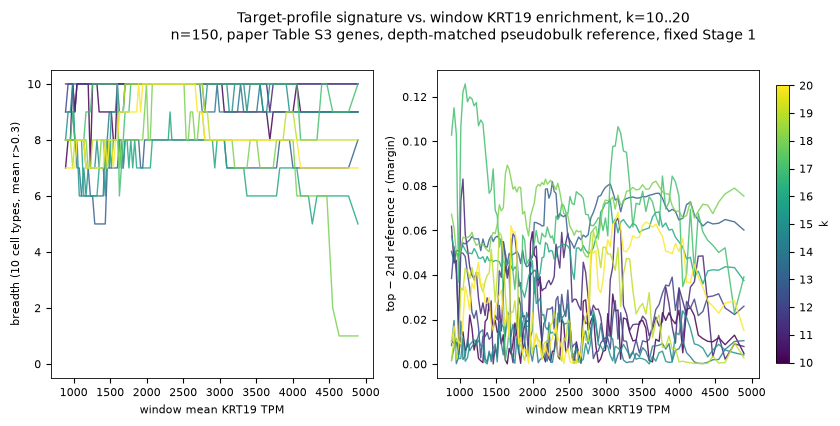

saved paper_duplication/figures/fig_sliding_window_k_sweep_paperGenes_properRef_breadth_margin.png


In [3]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
norm = Normalize(vmin=min(K_VALUES), vmax=max(K_VALUES))

for k in K_VALUES:
    sub = summary[summary["k"] == k].sort_values("mean_KRT19_tpm")
    color = viridis(norm(k))
    axes[0].plot(sub["mean_KRT19_tpm"], sub["breadth_celltypes_r_gt_0.3"], "-", color=color, linewidth=1.0, alpha=0.85)
    axes[1].plot(sub["mean_KRT19_tpm"], sub["reference_margin"], "-", color=color, linewidth=1.0, alpha=0.85)

axes[0].set_ylabel("breadth (10 cell types, mean r>0.3)")
axes[0].set_ylim(-0.5, 10.5)
axes[1].set_ylabel("top − 2nd reference r (margin)")
for ax in axes:
    ax.set_xlabel("window mean KRT19 TPM")

sm = plt.cm.ScalarMappable(cmap=viridis, norm=norm)
cbar = fig.colorbar(sm, ax=axes, ticks=K_VALUES, label="k", shrink=0.9, pad=0.02)

fig.suptitle("Target-profile signature vs. window KRT19 enrichment, k=10..20\n"
             "n=150, paper Table S3 genes, depth-matched pseudobulk reference, fixed Stage 1",
             y=1.03, fontsize=10)

figures_dir = Path("paper_duplication/figures")
figures_dir.mkdir(parents=True, exist_ok=True)
fig1_path = figures_dir / "fig_sliding_window_k_sweep_paperGenes_properRef_breadth_margin.png"
fig.savefig(fig1_path, dpi=200, bbox_inches="tight")
plt.show()
plt.close(fig)
print("saved", fig1_path)


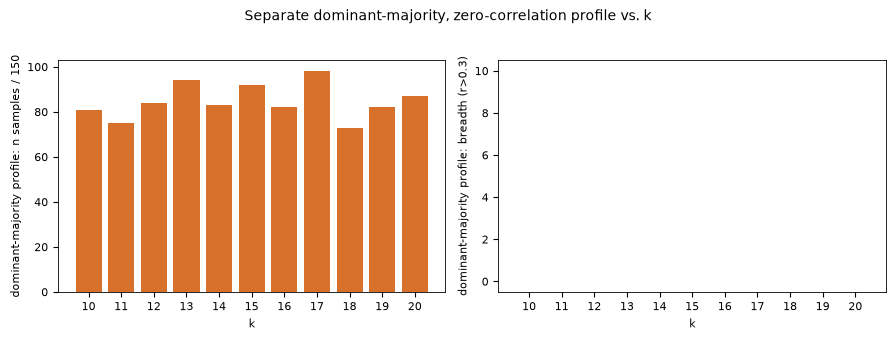

saved paper_duplication/figures/fig_sliding_window_k_sweep_paperGenes_properRef_dominant_profile.png


In [4]:
fig, axes = plt.subplots(1, 2, figsize=(9, 3.2))
ks = k_summary.index.to_numpy()

axes[0].bar(ks, k_summary["dominant_n"], color="#d6702a")
axes[0].set_ylabel("dominant-majority profile: n samples / 150")
axes[0].set_xlabel("k")
axes[0].set_xticks(ks)

axes[1].bar(ks, k_summary["dominant_profile_breadth"], color="#ab551c")
axes[1].set_ylabel("dominant-majority profile: breadth (r>0.3)")
axes[1].set_xlabel("k")
axes[1].set_xticks(ks)
axes[1].set_ylim(-0.5, 10.5)

fig.suptitle("Separate dominant-majority, zero-correlation profile vs. k", y=1.04, fontsize=10)
fig.tight_layout()
fig2_path = figures_dir / "fig_sliding_window_k_sweep_paperGenes_properRef_dominant_profile.png"
fig.savefig(fig2_path, dpi=200, bbox_inches="tight")
plt.show()
plt.close(fig)
print("saved", fig2_path)


**Interpretation**

* **Breadth (left panel above)** stays clustered near the top of its 0-10 range for essentially every k and every window — the same saturated pattern notebooks 05/06 found at k=9, now confirmed across the paper's entire reported stability-discussion range (k=10-20).
* **Margin (right panel above)** never exceeds ~0.13 (13% separation) at any k, and its trend with enrichment flips sign across k (-0.31 to +0.65) — there is no k where it behaves like a real, enrichable minority compartment sharpening into view.
* **The dominant-majority profile (second figure)** is remarkably stable in magnitude (73-98/150 samples, ~49-65%) and always exactly 0/10 breadth, at every single k — the profile *label* changes every time (it is a different specific `Profile_i` at every k, since profile numbering is fit-specific), but the underlying pattern does not.
* Combined with `large_k_EDA_paperGenes`'s earlier, non-sliding-window finding at k=14 (same relocate-not-resolve behavior) and notebooks 05/06's k=9 result, this sweep closes out k as an explanation across its full tested range, under the most paper-aligned combination of settings tried anywhere in this project (correct cohort + paper genes + proper reference + paper's own windowing mechanic, simultaneously).
